# Análisis Exploratorio de Datos (EDA) — Airbnb Bogotá
**Taller evaluativo 2 · Inteligencia de Negocios**

Este notebook corresponde a la fase de **Análisis Exploratorio de Datos** del proceso ETL.
Su objetivo es comprender la estructura, la calidad y la distribución de las tres colecciones
almacenadas en MongoDB (`Listings`, `Reviews`, `Calendar`) **antes** de definir las
transformaciones. Las decisiones que se derivan de aquí alimentan la clase `Transformacion`.

Fuente: Inside Airbnb — Bogotá


## 0. Configuración e importación de librerías

In [1]:
from pathlib import Path
import sys, warnings
warnings.filterwarnings("ignore")

BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(BASE_DIR))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 120)
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "font.size": 11})

## 1. Extracción desde MongoDB

Usamos la clase `Extraccion` del proyecto, que se conecta a la base local y devuelve un
DataFrame por colección. Si MongoDB no está disponible en este momento, el notebook cae a
los `.csv.gz` de `data/` **solo para poder ejecutarse**; el proceso ETL formal siempre usa Mongo.

In [2]:
try:
    from src.extraccion import Extraccion
    extraccion = Extraccion()
    datos = extraccion.extraer_todo()          
    listings = datos["listings"]
    reviews  = datos["reviews"]
    calendar = datos["calendar"]
    print("Datos extraídos desde MongoDB.")
except Exception as e:
    print(f"MongoDB no disponible ({type(e).__name__}). Cargando desde data/ como respaldo.")
    from src.config import DATA_DIR
    listings = pd.read_csv(DATA_DIR / "listings.csv.gz", low_memory=False)
    reviews  = pd.read_csv(DATA_DIR / "reviews.csv.gz",  low_memory=False)
    calendar = pd.read_csv(DATA_DIR / "calendar.csv.gz", low_memory=False)

print(f"Listings: {listings.shape[0]:,} filas x {listings.shape[1]} columnas")
print(f"Reviews : {reviews.shape[0]:,} filas x {reviews.shape[1]} columnas")
print(f"Calendar: {calendar.shape[0]:,} filas x {calendar.shape[1]} columnas")

2026-10-11 21:00:39 | INFO    | etl_airbnb.extraccion | Inicio de extracción desde MongoDB; base: airbnb_bogota_etl


2026-10-11 21:00:39 | INFO    | etl_airbnb.extraccion | Conexión establecida con MongoDB; base: airbnb_bogota_etl


2026-10-11 21:00:39 | INFO    | etl_airbnb.extraccion | Extrayendo colección Listings


2026-10-11 21:00:40 | INFO    | etl_airbnb.extraccion | Extracción completada: colección Listings, 19,187 registros y 90 columnas en 1.29 segundos


2026-10-11 21:00:40 | INFO    | etl_airbnb.extraccion | Extrayendo colección Reviews


2026-10-11 21:00:44 | INFO    | etl_airbnb.extraccion | Extracción completada: colección Reviews, 527,731 registros y 6 columnas en 3.83 segundos


2026-10-11 21:00:44 | INFO    | etl_airbnb.extraccion | Extrayendo colección Calendar


2026-10-11 21:01:38 | INFO    | etl_airbnb.extraccion | Extracción completada: colección Calendar, 7,003,255 registros y 5 columnas en 54.31 segundos


2026-10-11 21:01:38 | INFO    | etl_airbnb.extraccion | Conexión con MongoDB cerrada


Datos extraídos desde MongoDB.
Listings: 19,187 filas x 90 columnas
Reviews : 527,731 filas x 6 columnas
Calendar: 7,003,255 filas x 5 columnas


## 2. Entendimiento general de los datos

Para cada colección revisamos las primeras filas, el tamaño, los tipos de datos y una
descripción de las variables más relevantes.

### 2.1 Listings — primeras filas y estructura

In [3]:
listings.head()

,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,host_url,host_profile_id,host_profile_url,host_name,host_since,hosts_time_as_user_years,hosts_time_as_user_months,hosts_time_as_host_years,hosts_time_as_host_months,host_location,host_about,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_thumbnail_url,host_picture_url,host_neighbourhood,host_listings_count,host_total_listings_count,host_verifications,host_has_profile_pic,host_identity_verified,neighbourhood,neighbourhood_cleansed,neighbourhood_group_cleansed,latitude,longitude,property_type,room_type,accommodates,bathrooms,bathrooms_text,bedrooms,beds,amenities,price,price_quote_checkin_date,price_quote_checkout_date,price_quote_total_price,price_quote_price_per_night,price_quote_raw,minimum_nights,maximum_nights,minimum_minimum_nights,maximum_minimum_nights,minimum_maximum_nights,maximum_maximum_nights,minimum_nights_avg_ntm,maximum_nights_avg_ntm,calendar_updated,has_availability,availability_30,availability_60,availability_90,availability_365,calendar_last_scraped,number_of_reviews,number_of_reviews_ltm,number_of_reviews_l30d,availability_eoy,number_of_reviews_ly,estimated_occupancy_l365d,estimated_revenue_l365d,first_review,last_review,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,27841,https://www.airbnb.com/rooms/27841,20260621155658,2026-06-22,city scrape,Rosales Luxury Large 2BR Boutique Apt,Amazing bright 135m2 (1350 sq ft) apartment l...,None,https://a0.muscache.com/pictures/38377482/1df3...,113734,https://www.airbnb.com/users/show/113734,1462509905126026119,https://www.airbnb.com/users/profile/146250990...,Marcela,None,16,1,15.0,5.0,"Bogota, Colombia","I am an Architect and Urban Planner ,with my o...",None,None,None,t,None,https://a0.muscache.com/im/users/113734/profil...,None,3,None,None,t,t,None,Chapinero,None,4.657580,-74.05326,Entire serviced apartment,Entire home/apt,4,NaN,2.5 baths,2.0,3.0,"[""Blender"", ""Luggage dropoff allowed"", ""Long t...","$284,294.01",2027-04-01,2027-04-29,7960232.40,284294.01,"{""quote"": {""taxes"": null, ""currency"": ""COP"", ""...",28.0,1000.0,28.0,28.0,1000.0,1000.0,28.0,1000.0,None,t,0,0,0,82,2026-06-22,45,2,0,0,2,112,31840929.0,2010-10-06,2025-09-14,4.87,4.84,4.91,4.93,4.81,4.93,4.81,112727.0,None,3,3,0,0,0.24
1,65762,https://www.airbnb.com/rooms/65762,20260621155658,2026-06-22,city scrape,Apartaestudios La Candelaria,"In Bogota's historic center, near museums, res...",None,https://a0.muscache.com/pictures/miso/Hosting-...,321447,https://www.airbnb.com/users/show/321447,1462515641808590179,https://www.airbnb.com/users/profile/146251564...,Teresa,None,15,6,15.0,5.0,"Bogotá, Colombia",I'm a person that is always looking to enrich ...,None,None,None,t,None,https://a0.muscache.com/im/pictures/user/9bf8f...,None,24,None,None,t,t,None,Candelaria,None,4.594850,-74.07189,Entire loft,Entire home/apt,3,1.0,1 bath,1.0,1.0,"[""Blender"", ""Luggage dropoff allowed"", ""Long t...","$215,000.00",2026-06-27,2026-06-28,215000.00,215000.00,"{""quote"": {""taxes"": null, ""currency"": ""COP"", ""...",1.0,1125.0,1.0,1.0,1125.0,1125.0,1.0,1125.0,None,t,8,15,31,236,2026-06-22,33,0,0,67,1,0,0.0,2012-02-18,2025-04-28,4.75,4.67,4.81,4.91,4.73,4.79,4.70,100613.0,None,24,22,2,0,0.19
2,138660,https://www.airbnb.com/rooms/138660,20260621155658,2026-06-22,city scrape,Excelent Studio ROSALES/ ZONA G,Ideal place if you want to settle down in Bogo...,None,https://a0.muscache.com/pictures/24594394/1ace...,676823,https://www.airbnb.com/users/show/676823,1462513470872353935,https://www.airbnb.com/users/profile/146251347...,Carlos,None,15,0,15.0,0.0,"Bogota

In [4]:
listings.info(verbose=False)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19187 entries, 0 to 19186
Columns: 90 entries, id to reviews_per_month
dtypes: float64(27), int64(22), object(41)
memory usage: 13.2+ MB


In [5]:
# Variables numéricas más relevantes del negocio
cols_rel = ["accommodates", "bedrooms", "beds", "minimum_nights",
            "availability_365", "number_of_reviews", "review_scores_rating"]
listings[cols_rel].describe().round(2)

,accommodates,bedrooms,beds,minimum_nights,availability_365,number_of_reviews,review_scores_rating
count,19187.00,16228.00,18896.00,19183.00,19187.00,19187.0,14922.00
mean,3.11,1.54,1.95,6.98,306.95,27.5,4.70
std,2.09,1.60,2.09,10.99,82.07,74.0,0.47
min,1.00,1.00,1.00,1.00,0.00,0.0,1.00
25%,2.00,1.00,1.00,1.00,269.00,1.0,4.64
50%,2.00,1.00,1.00,1.00,349.00,8.0,4.83
75%,4.00,2.00,2.00,3.00,363.00,31.0,4.98
max,16.00,50.00,50.00,32.00,365.00,6162.0,5.00


### 2.2 Reviews — primeras filas y estructura

In [6]:
reviews.head()

,listing_id,id,date,reviewer_id,reviewer_name,comments
0,27841,113163,2010-10-06,121485,Paul,I really enjoyed staying at Marcela's place. I...
1,27841,143106,2010-11-22,288940,Vic,"I, Arrived an hour late from the airport. Mar..."
2,27841,172475,2011-01-19,98406,Matt,"Wonderful hosts, beautiful spacious apartment,..."
3,27841,225796,2011-04-13,471115,Tiffany,Marcela was a lovely and gracious host. She me...
4,27841,952928,2012-02-27,1098411,Sarah,Marcela is the perfect host and has a gorgeuos...


In [7]:
reviews.info(verbose=False)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 527731 entries, 0 to 527730
Columns: 6 entries, listing_id to comments
dtypes: int64(3), object(3)
memory usage: 24.2+ MB


### 2.3 Calendar — primeras filas y estructura

In [8]:
calendar.head()

,listing_id,date,available,minimum_nights,maximum_nights
0,15410909,2026-06-22,f,2,1125
1,15410909,2026-06-23,f,2,1125
2,15410909,2026-06-24,f,2,1125
3,15410909,2026-06-25,t,2,1125
4,15410909,2026-06-26,t,2,1125


In [9]:
calendar.info(verbose=False)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7003255 entries, 0 to 7003254
Columns: 5 entries, listing_id to maximum_nights
dtypes: int64(3), object(2)
memory usage: 267.2+ MB


## 3. Calidad de los datos

Analizamos valores nulos, duplicados y valores atípicos en las variables críticas.

### 3.1 Valores nulos o faltantes

En `Listings` hay columnas **completamente vacías** (100% nulos) que no aportan información
y deben descartarse en la transformación.

In [10]:
nulos_listings = (listings.isna().mean() * 100).round(1).sort_values(ascending=False)
print("Columnas 100% nulas en Listings:")
print(list(nulos_listings[nulos_listings == 100].index))
print(f"\nTotal columnas 100% nulas: {(nulos_listings == 100).sum()}")
nulos_listings.head(20)

Columnas 100% nulas en Listings:
['neighborhood_overview', 'host_since', 'host_response_time', 'host_thumbnail_url', 'host_acceptance_rate', 'host_response_rate', 'host_verifications', 'neighbourhood', 'host_total_listings_count', 'host_neighbourhood', 'calendar_updated', 'instant_bookable', 'neighbourhood_group_cleansed']

Total columnas 100% nulas: 13


neighborhood_overview           100.0
host_since                      100.0
host_response_time              100.0
host_thumbnail_url              100.0
host_acceptance_rate            100.0
host_response_rate              100.0
host_verifications              100.0
neighbourhood                   100.0
host_total_listings_count       100.0
host_neighbourhood              100.0
calendar_updated                100.0
instant_bookable                100.0
neighbourhood_group_cleansed    100.0
host_about                       45.9
host_location                    26.9
review_scores_accuracy           22.2
review_scores_value              22.2
review_scores_cleanliness        22.2
first_review                     22.2
review_scores_rating             22.2
dtype: float64

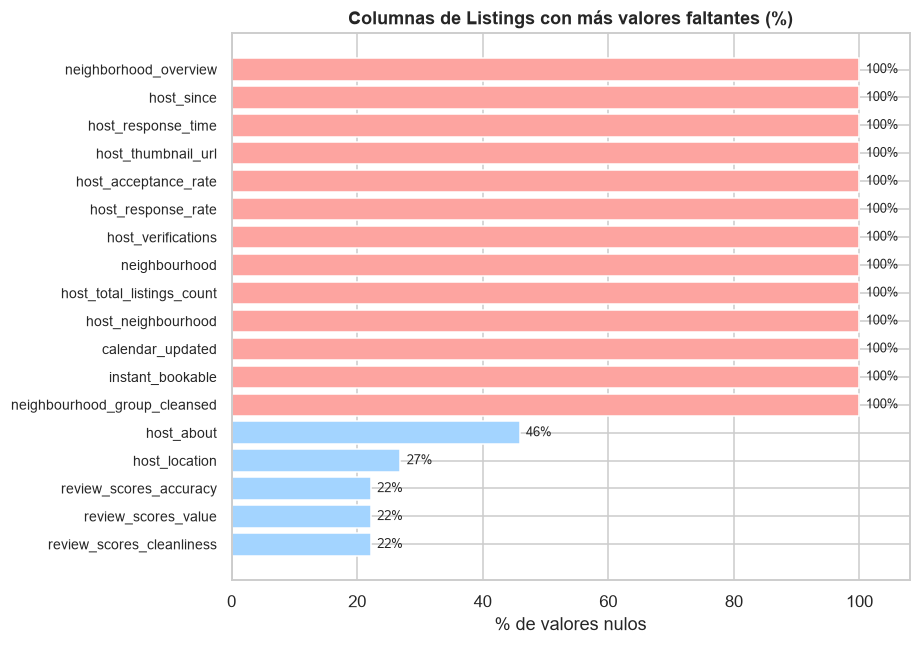

In [11]:
# Gráfica: columnas de Listings con más nulos
top_na = nulos_listings[nulos_listings > 0].head(18).iloc[::-1]
colores = ["#FDA4A0" if v == 100 else "#A3D4FF" for v in top_na.values]
fig, ax = plt.subplots(figsize=(8.5, 6))
ax.barh(range(len(top_na)), top_na.values, color=colores)
ax.set_yticks(range(len(top_na))); ax.set_yticklabels(top_na.index, fontsize=9)
ax.set_xlabel("% de valores nulos"); ax.set_xlim(0, 108)
ax.set_title("Columnas de Listings con más valores faltantes (%)")
for i, v in enumerate(top_na.values):
    ax.text(v + 1, i, f"{v:.0f}%", va="center", fontsize=8.5)
plt.tight_layout(); plt.show()

In [12]:
print("Nulos en Reviews (%):")
print((reviews.isna().mean()*100).round(3))
print("\nNulos en Calendar (%):")
print((calendar.isna().mean()*100).round(3))

Nulos en Reviews (%):


listing_id       0.000
id               0.000
date             0.000
reviewer_id      0.000
reviewer_name    0.000
comments         0.036
dtype: float64

Nulos en Calendar (%):


listing_id        0.0
date              0.0
available         0.0
minimum_nights    0.0
maximum_nights    0.0
dtype: float64


### 3.2 Registros duplicados

Verificamos duplicados por la llave natural de cada colección.

In [13]:
print("Listings duplicados por 'id':", int(listings.duplicated('id').sum()))
print("Listings filas completamente duplicadas:", int(listings.duplicated().sum()))
print("Reviews duplicados por 'id':", int(reviews.duplicated('id').sum()))
print("Calendar duplicados por ('listing_id','date'):",
      int(calendar.duplicated(['listing_id','date']).sum()))
print("Calendar filas completamente duplicadas:", int(calendar.duplicated().sum()))

Listings duplicados por 'id': 0


Listings filas completamente duplicadas: 0
Reviews duplicados por 'id': 0


Calendar duplicados por ('listing_id','date'): 0


Calendar filas completamente duplicadas: 0


### 3.3 Valores atípicos

El taller pide revisar `price`, `minimum_nights` y `availability_365`.
`price` llega como **texto con símbolos** (`$`, `,`), así que primero lo convertimos a número.

In [14]:

listings["price"] = pd.to_numeric(
    listings["price"].astype(str).str.replace(r"[^\d.]", "", regex=True).replace("", np.nan),
    errors="coerce")

p = listings["price"].dropna()
print("price (COP/noche):")
print(f"  mínimo: ${p.min():,.0f}   mediana: ${p.median():,.0f}   media: ${p.mean():,.0f}   máximo: ${p.max():,.0f}")
print(f"  p95: ${p.quantile(.95):,.0f}   p99: ${p.quantile(.99):,.0f}")
print(f"  valores <= 0: {(p<=0).sum()}   valores > 2.000.000: {(p>2_000_000).sum()}")

print("\nminimum_nights:")
mn = listings["minimum_nights"].dropna()
print(f"  mínimo: {mn.min()}   mediana: {mn.median():.0f}   máximo: {mn.max()}   > 365: {(mn>365).sum()}")

print("\navailability_365:")
av = listings["availability_365"].dropna()
print(f"  mínimo: {av.min()}   media: {av.mean():.0f}   máximo: {av.max()}   fuera de [0,365]: {((av<0)|(av>365)).sum()}")

price (COP/noche):
  mínimo: $19,181   mediana: $161,460   media: $446,027   máximo: $448,176,567
  p95: $497,580   p99: $1,330,087
  valores <= 0: 0   valores > 2.000.000: 90

minimum_nights:
  mínimo: 1.0   mediana: 1   máximo: 32.0   > 365: 0

availability_365:
  mínimo: 0   media: 307   máximo: 365   fuera de [0,365]: 0


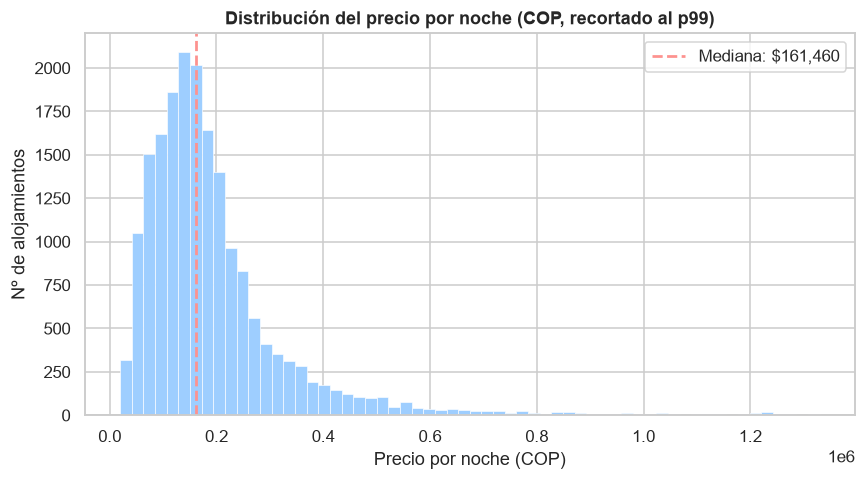

In [15]:

p99 = p.quantile(.99)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(p[p <= p99], bins=60, color="#9ECEFF", edgecolor="white", linewidth=.4)
ax.axvline(p.median(), color="#FD928F", ls="--", lw=1.8, label=f"Mediana: ${p.median():,.0f}")
ax.set_title("Distribución del precio por noche (COP, recortado al p99)")
ax.set_xlabel("Precio por noche (COP)"); ax.set_ylabel("Nº de alojamientos"); ax.legend()
plt.tight_layout(); plt.show()

## 4. Visualizaciones y hallazgos principales

### 4.1 Oferta y precio por localidad

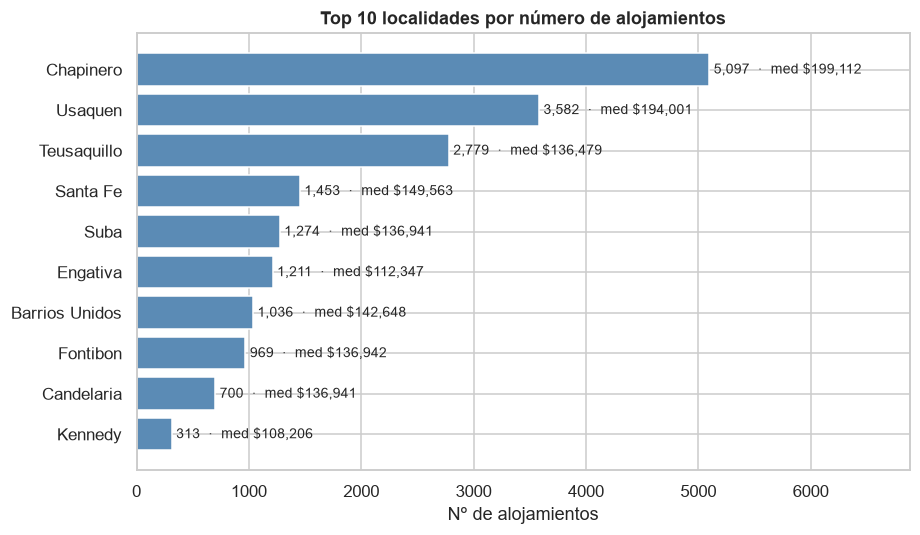

In [16]:
g = (listings.groupby("neighbourhood_cleansed")
     .agg(n=("id","size"), precio_med=("price","median"))
     .sort_values("n", ascending=False).head(10).iloc[::-1])
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.barh(range(len(g)), g["n"], color="#5B8BB5")
ax.set_yticks(range(len(g))); ax.set_yticklabels(g.index)
ax.set_title("Top 10 localidades por número de alojamientos")
ax.set_xlabel("Nº de alojamientos"); ax.set_xlim(0, g["n"].max()*1.35)
for i,(n,pm) in enumerate(zip(g["n"], g["precio_med"])):
    ax.text(n+40, i, f"{n:,}  ·  med ${pm:,.0f}", va="center", fontsize=9)
plt.tight_layout(); plt.show()

### 4.2 Tipo de habitación

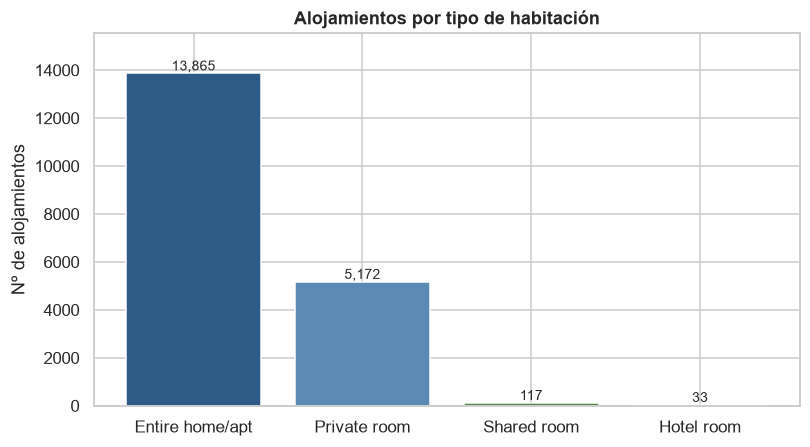

In [17]:
rt = listings["room_type"].value_counts()
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.bar(range(len(rt)), rt.values, color=["#2E5A87","#5B8BB5","#4E8542","#888888"][:len(rt)], edgecolor="white")
ax.set_xticks(range(len(rt))); ax.set_xticklabels(rt.index)
ax.set_title("Alojamientos por tipo de habitación"); ax.set_ylabel("Nº de alojamientos")
for i,v in enumerate(rt.values): ax.text(i, v+120, f"{v:,}", ha="center", fontsize=9)
ax.set_ylim(0, rt.max()*1.12); plt.tight_layout(); plt.show()

### 4.3 Estacionalidad de la ocupación (Calendar)

Marcamos como "ocupado" cada día con `available == 'f'` y promediamos por mes.

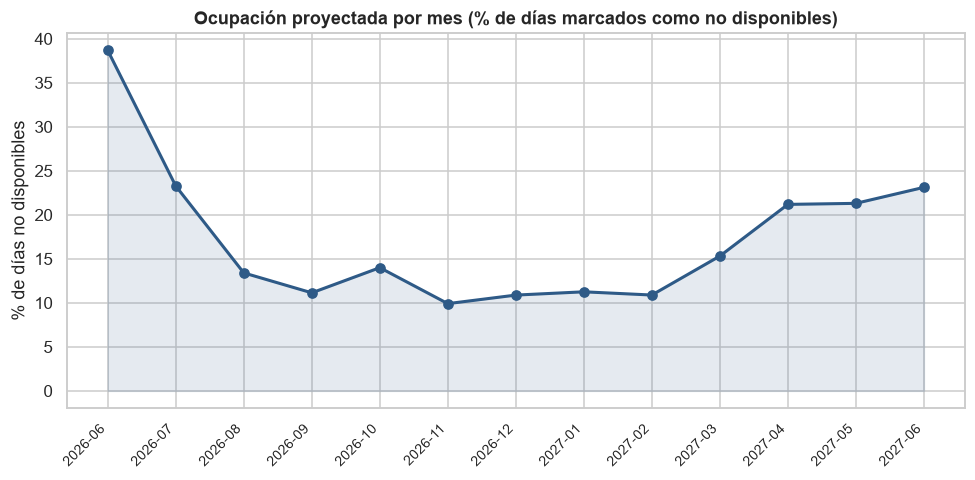

In [18]:
cal = calendar.copy()
cal["date"] = pd.to_datetime(cal["date"], errors="coerce")
cal["anio_mes"] = cal["date"].dt.to_period("M").astype(str)
cal["ocupado"] = (cal["available"] == "f").astype(int)
occ = cal.groupby("anio_mes")["ocupado"].mean().mul(100)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(range(len(occ)), occ.values, marker="o", color="#2E5A87", lw=2)
ax.fill_between(range(len(occ)), occ.values, alpha=.12, color="#2E5A87")
ax.set_xticks(range(len(occ))); ax.set_xticklabels(occ.index, rotation=45, ha="right", fontsize=9)
ax.set_title("Ocupación proyectada por mes (% de días marcados como no disponibles)")
ax.set_ylabel("% de días no disponibles"); plt.tight_layout(); plt.show()

> **Nota de interpretación.** La mayor "ocupación" aparece en los primeros meses del
> horizonte (junio–julio 2026) y vuelve a subir al final (2027). Es un comportamiento típico
> del calendario de Inside Airbnb: los meses cercanos a la fecha de captura ya tienen reservas
> y bloqueos, mientras que los meses intermedios lejanos aún no se han gestionado. **No debe
> leerse como una temporada turística de cierre de año.**

### 4.4 Reseñas por año

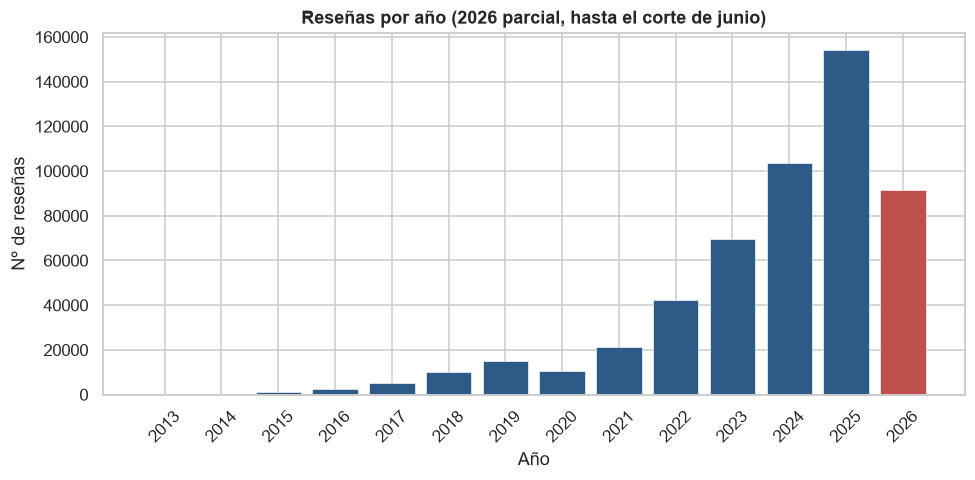

In [19]:
rev = reviews.copy()
rev["date"] = pd.to_datetime(rev["date"], errors="coerce")
ry = rev["date"].dt.year.value_counts().sort_index()
ry = ry[ry.index >= 2013]
fig, ax = plt.subplots(figsize=(9, 4.5))
cols = ["#C0504D" if a == 2026 else "#2E5A87" for a in ry.index]
ax.bar(ry.index.astype(int), ry.values, color=cols, edgecolor="white", linewidth=.4)
ax.set_title("Reseñas por año (2026 parcial, hasta el corte de junio)")
ax.set_ylabel("Nº de reseñas"); ax.set_xlabel("Año")
ax.set_xticks(ry.index.astype(int)); ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

### 4.5 Relación entre rango de precio y reseñas

                  reviews_prom  reviews_mes     n
categoria_precio                                 
Económico                21.11         1.21  4754
Moderado                 32.41         1.76  4746
Alto                     29.69         1.55  4744
Lujo                     27.34         1.24  4748


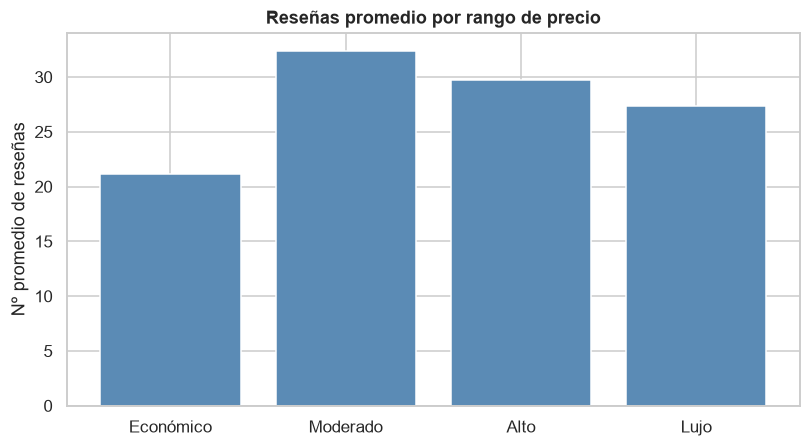

In [20]:
listings["categoria_precio"] = pd.qcut(listings["price"], 4,
                                       labels=["Económico","Moderado","Alto","Lujo"])
rel = (listings.groupby("categoria_precio", observed=True)
       .agg(reviews_prom=("number_of_reviews","mean"),
            reviews_mes=("reviews_per_month","mean"),
            n=("id","size")).round(2))
print(rel)
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.bar(range(len(rel)), rel["reviews_prom"], color="#5B8BB5", edgecolor="white")
ax.set_xticks(range(len(rel))); ax.set_xticklabels(rel.index)
ax.set_title("Reseñas promedio por rango de precio")
ax.set_ylabel("Nº promedio de reseñas"); plt.tight_layout(); plt.show()

## 5. Síntesis de hallazgos y decisiones para la transformación

**Calidad**
1. `Listings` trae **13 columnas 100% vacías** (`host_since`, `host_response_rate`,
   `host_verifications`, `neighbourhood`, `instant_bookable`, entre otras). Se descartan.
2. **No hay duplicados** por llave natural en ninguna colección, ni filas repetidas en
   `Calendar`. No se requiere deduplicación por disponibilidad diaria.
3. `price` llega como **texto con `$` y `,`**: requiere limpieza y conversión a numérico.
4. `price` **no tiene ceros ni negativos** (mínimo ≈ \$19.181). Sí tiene **atípicos altos
   reales** (máximo ≈ \$448M; 90 alojamientos sobre \$2M; p99 ≈ \$1,33M).
5. `minimum_nights` está **dentro de rango** (máximo real: 32). **No existen valores > 365**,
   por lo que un filtro `minimum_nights > 365` no elimina ningún registro.
6. `availability_365` está **íntegramente dentro de [0, 365]**.
7. `Reviews` casi no tiene nulos (191 comentarios vacíos, 0,04%).

**Decisiones que pasan a la fase de transformación**
- Convertir `price` a `float` quitando `$` y `,`.
- Convertir `date` (Calendar y Reviews) a formato `YYYY-MM-DD` y derivar `anio`, `mes`, `dia`, `trimestre`.
- Derivar `categoria_precio` por cuartiles (Económico / Moderado / Alto / Lujo).
- Descartar columnas 100% nulas en `Listings`.
- **Tratamiento de atípicos de precio (confirmado en la transformación):** los precios por encima
  del p99 (≈ \$1,33M; 190 alojamientos) se *marcan* en la columna `precio_atipico` y no se eliminan.
  Un precio extremo puede ser un error de digitación o una propiedad de lujo real; borrarlo sacaría
  el alojamiento también de los análisis que no dependen del precio (ubicación, reseñas, disponibilidad).
  Se descartó la regla IQR porque, con la cola larga de los precios de Bogotá, marcaba como atípico
  al 7% de los alojamientos (1.410), en su mayoría propiedades de lujo legítimas.
- Agregar `Calendar` por mes para el análisis de ocupación.